[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch07_Lab03_2026_Backpropagation_ChainRule_ByHand.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 7: Backpropagation by Hand** (Part II: Making It Learn).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=7](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=7)
* The simplified video course for kids that this book grew from: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# 🔗 Lab 03: Backpropagation by Hand — The Chain Rule Unboxed
## From `model.fit()` Magic to Doing the Math Yourself

**In Lab 02** we trained an MNIST network with one line: `model.fit(...)`. Keras silently did **backpropagation** thousands of times per second.

**In this lab** we shrink the network down to something you can compute with a pencil:

```
input ──► [ hidden neuron, sigmoid ] ──► [ output neuron ] ──► loss
  x          h = σ(w₁·x + b₁)              ŷ = w₂·h + b₂       L = (y − ŷ)²
```

**What you'll do:**
1. Run a forward pass with tiny, friendly numbers
2. Derive every gradient using the **chain rule** — one link at a time
3. Verify your calculus numerically (no faith required!)
4. Watch the network learn in a training loop
5. Confirm that Keras computes the *exact same gradients*

**Why one hidden neuron?** In Lab 01-style single-neuron gradient descent there is nothing to "propagate" — one link, one derivative. The moment we add a hidden layer, the output's error must travel **backward through** the hidden neuron to reach `w₁`. That backward journey *is* backpropagation.

---

> ### ✅ Checked edition (November 2026)
> This notebook was re-run top to bottom and checked for *The Why Book of Deep Learning, Part 1*. What changed from the original:
>
> * Cell 9 builds the Keras model with `tf.keras.Input(shape=(1,))` instead of the deprecated `input_shape=` (which printed a warning).
> * Lab 02's network has exactly 109,386 parameters and trains on batches of **128** images, not 32; the closing message now says so.
> * Everything else was checked and left as it was: every hand-computed gradient matches the numerical check and Keras's `GradientTape` to 7 decimal places.

## 📦 Cell 1: Imports (just NumPy + Matplotlib!)

No TensorFlow needed until the very end — the whole point is to see there's no magic inside.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

print("✅ Ready! Backprop needs nothing but arithmetic and the chain rule.")

✅ Ready! Backprop needs nothing but arithmetic and the chain rule.


---
## 🧠 Cell 2: Meet Our Tiny Network

Our network has exactly **4 trainable parameters**:

| Symbol | Meaning | Initial value |
|--------|---------|---------------|
| `w1` | input → hidden weight | 0.5 |
| `b1` | hidden bias | 0.0 |
| `w2` | hidden → output weight | 0.5 |
| `b2` | output bias | 0.0 |

The **hidden neuron** uses the sigmoid activation:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

Sigmoid has a beautiful property we'll need later — its derivative can be written using its *own output*:

$$\sigma'(z) = \sigma(z)\,\bigl(1 - \sigma(z)\bigr)$$

*(Try proving this at home — it's 3 lines of calculus and very satisfying.)*

In [2]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def sigmoid_derivative(z):
    s = sigmoid(z)
    return s * (1 - s)      # σ'(z) = σ(z)·(1 − σ(z))

# ---- Parameters (the 4 numbers the network will learn) ----
w1, b1 = 0.5, 0.0     # input  → hidden
w2, b2 = 0.5, 0.0     # hidden → output

# ---- One training example ----
x = 2.0               # input
y = 1.0               # target

print(f"Network: x ──[w1={w1}, b1={b1}]──► sigmoid ──[w2={w2}, b2={b2}]──► ŷ")
print(f"Training example: input x = {x}, target y = {y}")

Network: x ──[w1=0.5, b1=0.0]──► sigmoid ──[w2=0.5, b2=0.0]──► ŷ
Training example: input x = 2.0, target y = 1.0


---
## ➡️ Cell 3: The Forward Pass — Step by Step

We compute the output **left to right**, saving every intermediate value. (Backprop will need them — this is exactly why frameworks like TensorFlow cache activations during the forward pass!)

$$z_1 = w_1 x + b_1 \qquad h = \sigma(z_1) \qquad \hat{y} = w_2 h + b_2 \qquad L = (y - \hat{y})^2$$

In [3]:
# ---- Forward pass, one step at a time ----
z1 = w1 * x + b1          # Step 1: hidden pre-activation
h  = sigmoid(z1)          # Step 2: hidden activation
y_hat = w2 * h + b2       # Step 3: output (no activation — regression)
L  = (y - y_hat) ** 2     # Step 4: squared-error loss

print("FORWARD PASS")
print("=" * 50)
print(f"Step 1: z1 = w1·x + b1  = {w1}·{x} + {b1}  = {z1}")
print(f"Step 2: h  = σ(z1)      = σ({z1})       = {h:.6f}")
print(f"Step 3: ŷ  = w2·h + b2  = {w2}·{h:.4f} + {b2} = {y_hat:.6f}")
print(f"Step 4: L  = (y − ŷ)²   = ({y} − {y_hat:.4f})² = {L:.6f}")
print("=" * 50)
print(f"\nThe network predicts {y_hat:.4f} but we wanted {y}.")
print("Now: which of the 4 parameters is 'to blame', and by how much?")
print("That question is answered by... the CHAIN RULE. ⛓️")

FORWARD PASS
Step 1: z1 = w1·x + b1  = 0.5·2.0 + 0.0  = 1.0
Step 2: h  = σ(z1)      = σ(1.0)       = 0.731059
Step 3: ŷ  = w2·h + b2  = 0.5·0.7311 + 0.0 = 0.365529
Step 4: L  = (y − ŷ)²   = (1.0 − 0.3655)² = 0.402553

The network predicts 0.3655 but we wanted 1.0.
Now: which of the 4 parameters is 'to blame', and by how much?
That question is answered by... the CHAIN RULE. ⛓️


---
## ⛓️ Cell 4: The Chain Rule — Why We Need It

We want $\dfrac{\partial L}{\partial w_1}$: *"if I nudge `w1` a tiny bit, how much does the loss change?"*

But `w1` doesn't touch `L` directly! The influence flows through a **chain** of intermediate values:

$$w_1 \;\longrightarrow\; z_1 \;\longrightarrow\; h \;\longrightarrow\; \hat{y} \;\longrightarrow\; L$$

The chain rule says: **multiply the local derivatives along the path**:

$$\frac{\partial L}{\partial w_1} \;=\; \underbrace{\frac{\partial L}{\partial \hat{y}}}_{\text{how loss reacts to output}} \cdot \underbrace{\frac{\partial \hat{y}}{\partial h}}_{\text{how output reacts to hidden}} \cdot \underbrace{\frac{\partial h}{\partial z_1}}_{\text{how sigmoid reacts}} \cdot \underbrace{\frac{\partial z_1}{\partial w_1}}_{\text{how }z_1\text{ reacts to }w_1}$$

Each factor is a **one-step, local** derivative — easy calculus:

| Link | Expression | Derivative |
|------|-----------|------------|
| $\partial L / \partial \hat{y}$ | $L = (y-\hat{y})^2$ | $-2(y - \hat{y})$ |
| $\partial \hat{y} / \partial h$ | $\hat{y} = w_2 h + b_2$ | $w_2$ |
| $\partial h / \partial z_1$ | $h = \sigma(z_1)$ | $\sigma(z_1)(1-\sigma(z_1))$ |
| $\partial z_1 / \partial w_1$ | $z_1 = w_1 x + b_1$ | $x$ |

💡 **"Back-propagation" = evaluating this product from the loss end backward**, reusing shared prefixes as we go. Watch:

In [4]:
# ---- Backward pass: compute each LINK of the chain ----
print("BACKWARD PASS — one link at a time")
print("=" * 60)

# Link 1: loss w.r.t. output
dL_dyhat = -2 * (y - y_hat)
print(f"∂L/∂ŷ   = −2(y − ŷ)      = −2({y} − {y_hat:.4f}) = {dL_dyhat:.6f}")

# Link 2: output w.r.t. hidden activation
dyhat_dh = w2
print(f"∂ŷ/∂h   = w2                              = {dyhat_dh:.6f}")

# Link 3: hidden activation w.r.t. pre-activation (sigmoid slope)
dh_dz1 = sigmoid_derivative(z1)
print(f"∂h/∂z1  = σ(z1)·(1−σ(z1)) = {h:.4f}·{1-h:.4f}  = {dh_dz1:.6f}")

# Link 4: pre-activation w.r.t. each parameter
dz1_dw1 = x
dz1_db1 = 1.0
print(f"∂z1/∂w1 = x                               = {dz1_dw1:.6f}")
print(f"∂z1/∂b1 = 1                               = {dz1_db1:.6f}")

print("=" * 60)
print("\nNow MULTIPLY the links (this is the chain rule in action):\n")

# ---- Gradients for the OUTPUT layer (short chains) ----
dL_dw2 = dL_dyhat * h        # ∂L/∂w2 = ∂L/∂ŷ · ∂ŷ/∂w2,  and ∂ŷ/∂w2 = h
dL_db2 = dL_dyhat * 1.0      # ∂ŷ/∂b2 = 1

# ---- Gradients for the HIDDEN layer (the long chains!) ----
dL_dh  = dL_dyhat * dyhat_dh          # error arriving AT the hidden neuron
dL_dz1 = dL_dh * dh_dz1               # ...pushed through the sigmoid
dL_dw1 = dL_dz1 * dz1_dw1             # ...arriving at w1
dL_db1 = dL_dz1 * dz1_db1             # ...arriving at b1

print(f"∂L/∂w2 = ∂L/∂ŷ · h              = {dL_dyhat:.4f} · {h:.4f} = {dL_dw2:.6f}")
print(f"∂L/∂b2 = ∂L/∂ŷ · 1              = {dL_db2:.6f}")
print(f"∂L/∂h  = ∂L/∂ŷ · w2             = {dL_dyhat:.4f} · {w2}   = {dL_dh:.6f}   ◄ error flows BACKWARD into hidden layer")
print(f"∂L/∂z1 = ∂L/∂h · σ'(z1)         = {dL_dh:.4f} · {dh_dz1:.4f} = {dL_dz1:.6f}")
print(f"∂L/∂w1 = ∂L/∂z1 · x             = {dL_dz1:.4f} · {x}   = {dL_dw1:.6f}")
print(f"∂L/∂b1 = ∂L/∂z1 · 1             = {dL_db1:.6f}")

print("\n🔑 KEY INSIGHT: to get ∂L/∂w1 we REUSED ∂L/∂ŷ, then ∂L/∂h, then ∂L/∂z1.")
print("   Backprop = chain rule + never computing the same piece twice.")

BACKWARD PASS — one link at a time
∂L/∂ŷ   = −2(y − ŷ)      = −2(1.0 − 0.3655) = -1.268941
∂ŷ/∂h   = w2                              = 0.500000
∂h/∂z1  = σ(z1)·(1−σ(z1)) = 0.7311·0.2689  = 0.196612
∂z1/∂w1 = x                               = 2.000000
∂z1/∂b1 = 1                               = 1.000000

Now MULTIPLY the links (this is the chain rule in action):

∂L/∂w2 = ∂L/∂ŷ · h              = -1.2689 · 0.7311 = -0.927671
∂L/∂b2 = ∂L/∂ŷ · 1              = -1.268941
∂L/∂h  = ∂L/∂ŷ · w2             = -1.2689 · 0.5   = -0.634471   ◄ error flows BACKWARD into hidden layer
∂L/∂z1 = ∂L/∂h · σ'(z1)         = -0.6345 · 0.1966 = -0.124745
∂L/∂w1 = ∂L/∂z1 · x             = -0.1247 · 2.0   = -0.249489
∂L/∂b1 = ∂L/∂z1 · 1             = -0.124745

🔑 KEY INSIGHT: to get ∂L/∂w1 we REUSED ∂L/∂ŷ, then ∂L/∂h, then ∂L/∂z1.
   Backprop = chain rule + never computing the same piece twice.


---
## 🧭 Cell 5: So... What Did We Just Find Out?

Cell 4 produced four numbers. Numbers are not understanding — so let's answer the three questions that matter:

**Question 1 — What did we find out?**
For each parameter, its gradient is a **sensitivity multiplier**: nudge that knob by a tiny amount, and the loss moves by (gradient × nudge). Four knobs, four blame reports.

**Question 2 — What is the significance?**
Read each gradient in two parts:
- **The sign** tells the *direction*: negative means "turning this knob UP brings the loss DOWN."
- **The magnitude** tells the *influence*: a bigger absolute value means this knob matters more to the error right now.

**Question 3 — Now change what, by how much?**
All of them, simultaneously — each in its own downhill direction, each in proportion to its own gradient:

$$p \;\leftarrow\; p - \eta \cdot \frac{\partial L}{\partial p} \qquad \text{for every parameter } p$$

The learning rate η sets the stride. Let's execute **one single update step** and watch the prediction improve before our eyes.

In [5]:
gradients = {"w1": dL_dw1, "b1": dL_db1, "w2": dL_dw2, "b2": dL_db2}

# ---------- Q1 & Q2: the blame report ----------
print("THE BLAME REPORT \u2014 what each gradient tells us")
print("=" * 70)
print(f"{'param':<7}{'\u2202L/\u2202p':>13}   how to read it")
print("-" * 70)
for name, g in gradients.items():
    move = "INCREASE" if g < 0 else "DECREASE"
    print(f"{name:<7}{g:>13.6f}   nudge {name} up \u2192 loss goes {'DOWN' if g < 0 else 'UP'}  \u21d2  {move} {name}")
print("=" * 70)

print("\nINFLUENCE RANKING (by |gradient|) \u2014 who matters most right now?")
for rank, (name, g) in enumerate(sorted(gradients.items(), key=lambda kv: -abs(kv[1])), 1):
    bar = "\u2588" * int(abs(g) * 20)
    print(f"  {rank}. {name}: |{g:.4f}|  {bar}")
print("  \u2192 b2 is the most influential knob at this moment; b1 the least.")
print("    (Why is w1's influence small? Its error signal was taxed by the")
print("     sigmoid's slope of ~0.197 on the way back. Remember this!)")

# ---------- Q3: one gradient-descent step ----------
eta = 0.5
print(f"\nONE UPDATE STEP  (p \u2190 p \u2212 \u03b7\u00b7\u2202L/\u2202p, with \u03b7 = {eta})")
print("=" * 70)
w1_new = w1 - eta * dL_dw1
b1_new = b1 - eta * dL_db1
w2_new = w2 - eta * dL_dw2
b2_new = b2 - eta * dL_db2
for name, old, g, new in [("w1", w1, dL_dw1, w1_new), ("b1", b1, dL_db1, b1_new),
                          ("w2", w2, dL_dw2, w2_new), ("b2", b2, dL_db2, b2_new)]:
    print(f"  {name}: {old:.4f}  \u2212  {eta}\u00b7({g:+.4f})  =  {new:.4f}")

# ---------- Did it help? Re-run the forward pass with the NEW parameters ----------
z1_new    = w1_new * x + b1_new
h_new     = sigmoid(z1_new)
y_hat_new = w2_new * h_new + b2_new
L_new     = (y - y_hat_new) ** 2

print("\nBEFORE vs. AFTER one step:")
print("=" * 70)
print(f"  prediction \u0177 : {y_hat:.4f}  \u2192  {y_hat_new:.4f}   (target y = {y})")
print(f"  loss L       : {L:.4f}  \u2192  {L_new:.4f}   ({(1 - L_new/L)*100:.0f}% of the error gone in ONE step!)")
print("=" * 70)
print("\n\U0001f440 Interesting \u2014 we jumped PAST the target (\u0177 > 1). Our stride \u03b7 = 0.5 is")
print("   a bit aggressive. Hold that thought for the training loop in Cell 7.")
print("\n(Note: we stored the results in NEW variables \u2014 w1, b1, w2, b2 are untouched,")
print(" because the next cell still needs the gradients at the ORIGINAL point.)")

THE BLAME REPORT — what each gradient tells us
param          ∂L/∂p   how to read it
----------------------------------------------------------------------
w1         -0.249489   nudge w1 up → loss goes DOWN  ⇒  INCREASE w1
b1         -0.124745   nudge b1 up → loss goes DOWN  ⇒  INCREASE b1
w2         -0.927671   nudge w2 up → loss goes DOWN  ⇒  INCREASE w2
b2         -1.268941   nudge b2 up → loss goes DOWN  ⇒  INCREASE b2

INFLUENCE RANKING (by |gradient|) — who matters most right now?
  1. b2: |-1.2689|  █████████████████████████
  2. w2: |-0.9277|  ██████████████████
  3. w1: |-0.2495|  ████
  4. b1: |-0.1247|  ██
  → b2 is the most influential knob at this moment; b1 the least.
    (Why is w1's influence small? Its error signal was taxed by the
     sigmoid's slope of ~0.197 on the way back. Remember this!)

ONE UPDATE STEP  (p ← p − η·∂L/∂p, with η = 0.5)
  w1: 0.5000  −  0.5·(-0.2495)  =  0.6247
  b1: 0.0000  −  0.5·(-0.1247)  =  0.0624
  w2: 0.5000  −  0.5·(-0.9277)  =  0.9638


---
## 🔬 Cell 6: Trust, but Verify — Numerical Gradient Check

We just bet a real update step on those four gradients — and it paid off. But should we *trust* numbers derived on a whiteboard? Calculus says $\dfrac{\partial L}{\partial w_1} \approx \dfrac{L(w_1 + \varepsilon) - L(w_1 - \varepsilon)}{2\varepsilon}$ for tiny $\varepsilon$.

So let's *literally nudge each parameter*, re-run the forward pass, and see if the loss changes at the rate our chain rule predicted.

This version shows **everything**: for each nudge you'll see the exact parameter values used, then the full forward trace (z₁ → h → ŷ → L) printed to 10 decimal places — because the changes are microscopic and live in the last digits. Compare the +ε and −ε traces line by line and watch where the wiggle enters the network.

If the measured slope matches the chain-rule answer to ~7 decimal places, our calculus is correct. (Real ML engineers use this exact trick — it's called **gradient checking** — to debug hand-written backprop.)

In [6]:
def forward_verbose(w1_, b1_, w2_, b2_, x_, y_):
    """Forward pass that returns EVERY intermediate value, not just the loss."""
    z1_    = w1_ * x_ + b1_
    h_     = sigmoid(z1_)
    y_hat_ = w2_ * h_ + b2_
    L_     = (y_ - y_hat_) ** 2
    return z1_, h_, y_hat_, L_

eps = 1e-6

print("SETUP")
print("=" * 74)
print(f"Inputs     : x = {x},  target y = {y}")
print(f"Parameters : w1 = {w1},  b1 = {b1},  w2 = {w2},  b2 = {b2}")
print(f"Nudge size : \u03b5 = {eps}")

z1_0, h_0, yhat_0, L_0 = forward_verbose(w1, b1, w2, b2, x, y)
print()
print("BASELINE forward pass (no nudge):")
print(f"   z1 = {z1_0:.10f}   h = {h_0:.10f}")
print(f"   \u0177  = {yhat_0:.10f}   L = {L_0:.10f}")
print("   (10 decimals shown \u2014 the nudges are TINY, so watch the LAST digits!)")

# name -> (chain-rule gradient from Cell 4, nudged parameter tuple)
params = {
    "w1": (dL_dw1, lambda e: (w1 + e, b1, w2, b2)),
    "b1": (dL_db1, lambda e: (w1, b1 + e, w2, b2)),
    "w2": (dL_dw2, lambda e: (w1, b1, w2 + e, b2)),
    "b2": (dL_db2, lambda e: (w1, b1, w2, b2 + e)),
}

results = []
for name, (analytic, nudge) in params.items():
    print()
    print("=" * 74)
    print(f"NUDGING {name}   (chain rule predicts \u2202L/\u2202{name} = {analytic:.8f})")
    print("=" * 74)

    traces = {}
    for sign, label in [(+1, f"{name} + \u03b5"), (-1, f"{name} \u2212 \u03b5")]:
        pw1, pb1, pw2, pb2 = nudge(sign * eps)
        z1_, h_, yhat_, L_ = forward_verbose(pw1, pb1, pw2, pb2, x, y)
        traces[sign] = L_
        print(f"  {label}:")
        print(f"     inputs : w1={pw1:.7f}  b1={pb1:.7f}  w2={pw2:.7f}  b2={pb2:.7f}")
        print(f"     forward: z1 = {z1_:.10f}   h = {h_:.10f}")
        print(f"              \u0177  = {yhat_:.10f}   L = {L_:.10f}")

    rise = traces[+1] - traces[-1]
    numerical = rise / (2 * eps)
    ok = "\u2705" if abs(analytic - numerical) < 1e-5 else "\u274c"
    print(f"  Rise  : L(+\u03b5) \u2212 L(\u2212\u03b5) = {rise:+.10f}")
    print(f"  Run   : 2\u03b5 = {2*eps}")
    print(f"  Slope : rise/run = {numerical:.8f}   vs. chain rule {analytic:.8f}   {ok}")
    results.append((name, analytic, numerical, ok))

print()
print("SUMMARY \u2014 chain rule vs. brute-force nudging")
print("=" * 62)
print(f"{'param':<6}{'chain rule':>16}{'numerical':>16}{'match?':>10}")
print("-" * 62)
for name, analytic, numerical, ok in results:
    print(f"{name:<6}{analytic:>16.8f}{numerical:>16.8f}{ok:>9}")
print("=" * 62)
print()
print("\U0001f4cc Notice: when we nudged w2 or b2, z1 and h did NOT change at all \u2014")
print("   those parameters sit AFTER the hidden layer, so their wiggle only")
print("   enters at \u0177. The forward traces literally show the network's wiring!")
print()
print("The chain rule isn't a belief system \u2014 it's checkable arithmetic. \U0001f389")

SETUP
Inputs     : x = 2.0,  target y = 1.0
Parameters : w1 = 0.5,  b1 = 0.0,  w2 = 0.5,  b2 = 0.0
Nudge size : ε = 1e-06

BASELINE forward pass (no nudge):
   z1 = 1.0000000000   h = 0.7310585786
   ŷ  = 0.3655292893   L = 0.4025530827
   (10 decimals shown — the nudges are TINY, so watch the LAST digits!)

NUDGING w1   (chain rule predicts ∂L/∂w1 = -0.24948903)
  w1 + ε:
     inputs : w1=0.5000010  b1=0.0000000  w2=0.5000000  b2=0.0000000
     forward: z1 = 1.0000020000   h = 0.7310589719
              ŷ  = 0.3655294859   L = 0.4025528332
  w1 − ε:
     inputs : w1=0.4999990  b1=0.0000000  w2=0.5000000  b2=0.0000000
     forward: z1 = 0.9999980000   h = 0.7310581854
              ŷ  = 0.3655290927   L = 0.4025533322
  Rise  : L(+ε) − L(−ε) = -0.0000004990
  Run   : 2ε = 2e-06
  Slope : rise/run = -0.24948903   vs. chain rule -0.24948903   ✅

NUDGING b1   (chain rule predicts ∂L/∂b1 = -0.12474451)
  b1 + ε:
     inputs : w1=0.5000000  b1=0.0000010  w2=0.5000000  b2=0.0000000
     forw

---
## 🏋️ Cell 7: Put It in a Loop — Watch the Network Learn

Now we repeat **forward → backward → update** many times. The update rule is plain gradient descent, same as Lab 01:

$$w \leftarrow w - \eta \cdot \frac{\partial L}{\partial w}$$

where $\eta$ (eta) is the **learning rate**.

In [7]:
# ---- Re-initialize so this cell is self-contained ----
w1, b1 = 0.5, 0.0
w2, b2 = 0.5, 0.0
x, y   = 2.0, 1.0
eta    = 0.5          # learning rate
epochs = 60

loss_history, yhat_history = [], []

for epoch in range(epochs):
    # ---------- FORWARD ----------
    z1    = w1 * x + b1
    h     = sigmoid(z1)
    y_hat = w2 * h + b2
    L     = (y - y_hat) ** 2

    # ---------- BACKWARD (the 4 gradients, via chain rule) ----------
    dL_dyhat = -2 * (y - y_hat)

    dL_dw2 = dL_dyhat * h
    dL_db2 = dL_dyhat

    dL_dz1 = dL_dyhat * w2 * sigmoid_derivative(z1)   # error propagated back
    dL_dw1 = dL_dz1 * x
    dL_db1 = dL_dz1

    # ---------- UPDATE ----------
    w1 -= eta * dL_dw1
    b1 -= eta * dL_db1
    w2 -= eta * dL_dw2
    b2 -= eta * dL_db2

    loss_history.append(L)
    yhat_history.append(y_hat)

    if epoch < 5 or (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1:>3}:  ŷ = {y_hat:.5f}   L = {L:.7f}")

print(f"\n🎯 Target was y = {y}.  Final prediction: ŷ = {y_hat:.5f}")
print(f"Learned parameters: w1={w1:.4f}, b1={b1:.4f}, w2={w2:.4f}, b2={b2:.4f}")

Epoch   1:  ŷ = 0.36553   L = 0.4025531
Epoch   2:  ŷ = 1.39380   L = 0.1550813
Epoch   3:  ŷ = 0.71779   L = 0.0796445
Epoch   4:  ŷ = 1.17988   L = 0.0323554
Epoch   5:  ŷ = 0.87615   L = 0.0153398
Epoch  10:  ŷ = 1.01604   L = 0.0002574
Epoch  20:  ŷ = 1.00028   L = 0.0000001
Epoch  30:  ŷ = 1.00000   L = 0.0000000
Epoch  40:  ŷ = 1.00000   L = 0.0000000
Epoch  50:  ŷ = 1.00000   L = 0.0000000
Epoch  60:  ŷ = 1.00000   L = 0.0000000

🎯 Target was y = 1.0.  Final prediction: ŷ = 1.00000
Learned parameters: w1=0.5342, b1=0.0171, w2=0.7769, b2=0.4192


---
## 📉 Cell 8: Visualize the Learning

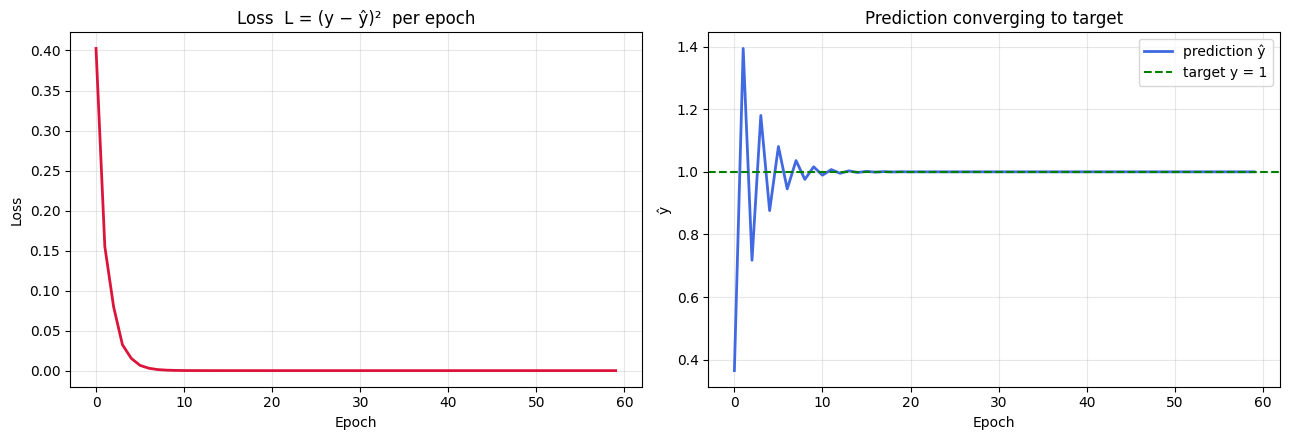

Every drop in that loss curve = one forward pass + one backward chain-rule sweep + one update.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(loss_history, lw=2, color='crimson')
axes[0].set_title("Loss  L = (y − ŷ)²  per epoch")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].grid(alpha=0.3)

axes[1].plot(yhat_history, lw=2, color='royalblue', label='prediction ŷ')
axes[1].axhline(1.0, color='green', ls='--', label='target y = 1')
axes[1].set_title("Prediction converging to target")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("ŷ")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Every drop in that loss curve = one forward pass + one backward chain-rule sweep + one update.")

---
## 🤝 Cell 9: Does Keras Agree With Our Pencil Math?

The ultimate test: build the *identical* network in TensorFlow/Keras, set the *identical* weights, and ask its automatic-differentiation engine (`GradientTape`) for the gradients. If backprop is what we think it is, the numbers must match **exactly**.

In [9]:
import tensorflow as tf

# ---- Same starting point as Cell 3 ----
w1_0, b1_0, w2_0, b2_0 = 0.5, 0.0, 0.5, 0.0
x_t = tf.constant([[2.0]])
y_t = tf.constant([[1.0]])

model = tf.keras.Sequential([
    tf.keras.Input(shape=(1,)),
    tf.keras.layers.Dense(1, activation='sigmoid'),                    # hidden
    tf.keras.layers.Dense(1)                                            # output
])
model.layers[0].set_weights([np.array([[w1_0]]), np.array([b1_0])])
model.layers[1].set_weights([np.array([[w2_0]]), np.array([b2_0])])

with tf.GradientTape() as tape:
    y_pred = model(x_t)
    loss = tf.reduce_mean((y_t - y_pred) ** 2)

grads = tape.gradient(loss, model.trainable_variables)
k_dw1, k_db1, k_dw2, k_db2 = [float(np.squeeze(g)) for g in grads]

# ---- Our hand computation (same as Cell 4, recomputed fresh) ----
z1 = w1_0 * 2.0 + b1_0
h  = sigmoid(z1)
y_hat = w2_0 * h + b2_0
dL_dyhat = -2 * (1.0 - y_hat)
hand_dw2 = dL_dyhat * h
hand_db2 = dL_dyhat
hand_dz1 = dL_dyhat * w2_0 * sigmoid_derivative(z1)
hand_dw1 = hand_dz1 * 2.0
hand_db1 = hand_dz1

print("HAND-COMPUTED vs. KERAS GradientTape")
print("=" * 58)
print(f"{'param':<6}{'by hand':>16}{'Keras':>16}{'match?':>10}")
print("-" * 58)
for name, hand, keras_g in [("w1", hand_dw1, k_dw1), ("b1", hand_db1, k_db1),
                            ("w2", hand_dw2, k_dw2), ("b2", hand_db2, k_db2)]:
    ok = "✅" if abs(hand - keras_g) < 1e-5 else "❌"
    print(f"{name:<6}{hand:>16.8f}{keras_g:>16.8f}{ok:>9}")
print("=" * 58)
print("\n🤯 model.fit() in Lab 02 was doing EXACTLY this chain-rule math —")
print("   just for 109,386 parameters instead of 4, on batches of 128 images.")

HAND-COMPUTED vs. KERAS GradientTape
param          by hand           Keras    match?
----------------------------------------------------------
w1         -0.24948903     -0.24948901        ✅
b1         -0.12474451     -0.12474450        ✅
w2         -0.92767051     -0.92767054        ✅
b2         -1.26894142     -1.26894140        ✅

🤯 model.fit() in Lab 02 was doing EXACTLY this chain-rule math —
   just for 109,386 parameters instead of 4, on batches of 128 images.


---
## 🎓 Cell 10: Summary & Homework

**What we learned:**

| Concept | Where you saw it |
|---------|------------------|
| Forward pass caches intermediate values | Cell 3 |
| Chain rule = multiply local derivatives along the path | Cell 4 |
| Backprop = chain rule evaluated backward, reusing shared terms | Cell 4 |
| Reading a gradient: sign = direction, magnitude = influence | Cell 5 |
| One update step: p ← p − η·∂L/∂p | Cell 5 |
| Gradient checking (numerical verification) | Cell 6 |
| Training loop: forward → backward → update | Cell 7 |
| Keras/TensorFlow does the identical math automatically | Cell 9 |

**The one-sentence takeaway:**
> Backpropagation is nothing but the chain rule, organized so that each layer's gradient reuses the gradient already computed for the layer after it.

**📝 Homework (try before next class):**
1. Change the hidden activation from sigmoid to **ReLU** (`max(0, z)`, derivative = 1 if z>0 else 0). Which lines of the backward pass change?
2. Add a **second hidden neuron**. Hint: `∂L/∂h` now arrives at *two* neurons — the chain rule turns into a *sum over paths*.
3. Set `eta = 5.0` in Cell 7 and rerun. What happens to the loss curve, and why?
4. In Cell 4, why did we compute `∂L/∂h` before `∂L/∂w1`? What would we waste if we computed each parameter's chain from scratch?

---
✨ *Next lab: from 4 parameters to 100,000 — backprop with matrices (vectorized layers).* ✨